In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")


✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.4 エミュレータでのやり方 (*Running on QEMU with OVMF*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/1/1.4_Running_on_QEMU_OVMF.ipynb)

---

### 🎯 本節の学習目標 (Learning Objectives)
1. **エミュレータ開発の動機と本質**: なぜ OS 自作において実機再起動ではなく仮想マシン（QEMU）が必須の武器となるのかを理解する。
2. **QEMU & OVMF アーキテクチャの完全把握**: 仮想 CPU / RAM / チップセットのエミュレーション機構と、オープンソース UEFI ファームウェア **OVMF** (*Open Virtual Machine Firmware*) の Flash ROM マッピング（`OVMF_CODE.fd` と `OVMF_VARS.fd` の分離）を導出する。
3. **仮想 FAT (`fat:rw:...`) のオンザフライ合成メカニズム**: ディスクイメージ（`.img`）を手動作成・ループバックマウントすることなく、ホスト上の通常ディレクトリを即座に FAT32 ブロックデバイスとして認識させる QEMU 内部構造を解明する。
4. **完全なブートシーケンスの追跡**: 電源投入時の CPU リセットベクタ `0xFFFFFFF0` から、SEC / PEI / DXE / BDS フェーズを経て ESP パーティション内の `\EFI\BOOT\BOOTX64.EFI` がメモリ展開されて `EfiMain` へジャンプするまでのレジスタ・メモリ変化を実証する。
5. **QEMU モニタによる低レイヤ検査**: `info registers`, `xp`, `info pci` を用いて、OS 開発初期の「画面に何も映らない世界」でハードウェア状態を可視化する最強のデバッグ手法を習得する。


## 1. なぜエミュレータを使うのか？ — 実機再起動地獄からの解放と開発ループ

### 実機ブート開発の抱える課題・限界 (Prior Limitations)
前節（1.1〜1.3）では、USB メモリに `BOOTX64.EFI` を書き込み、実機 PC を再起動して UEFI ブートメニューから起動する手順を学びました。しかし、OS 開発を本格的に進めると、実機テストには以下の**致命的なボトルネック**が存在することが明らかになります：

1. **長大なイテレーション時間**: ソースコードを1行変更してビルドするたびに、PC のシャットダウン・UEFI 起動ロゴ待機・ブートデバイス選択を行う必要があり、1回の実験に数分〜十数分を要します。
2. **「ブラックアウト」時の不可視性**: 初期カーネルでポインタの参照先を誤ったりページフォルトが発生すると、画面には何も表示されず（真っ暗のまま）PC がフリーズまたは無限再起動ループに陥ります。実機には `printf` もデバッガも繋がっていないため、どこで落ちたのかが全く分かりません。
3. **ハードウェア誤破壊・書き換えのリスク**: コマンドの打ち間違い（`dd` コマンドの出力先誤り等）により、開発マシンのホスト OS ドライブ（Windows や Linux のシステムパーティション）を誤って破壊してしまう危険が常につきまといます。

### QEMU による仮想化アプローチ
**QEMU** (*Quick EMUlator*) は、オープンソースの高機能プロセッサエミュレータ＆汎用仮想マシンモニタです。ホスト OS 上の通常のユーザプロセスとして仮想マザーボード、x86-64 CPU、メインメモリ、PCI バス、USB ホストコントローラ（xHCI）、グラフィックスカード（GOP フレームバッファ）をエミュレートします。

```mermaid
graph TD
    subgraph Host [ホスト OS (Linux / WSL2 / macOS)]
        DevDir[作業ディレクトリ<br/>disk_img/EFI/BOOT/BOOTX64.EFI] -->|ディレクトリ指定| QemuProc
        OVMF_ROM[UEFI ROM ファイル<br/>OVMF_CODE.fd / OVMF_VARS.fd] -->|Flash マッピング| QemuProc
        QemuProc[QEMU プロセス<br/>qemu-system-x86_64] -->|ウィンドウ表示| HostScreen[ホスト画面 (GOP 出力)]
        QemuProc <-->|対話コンソール| QemuMon[QEMU モニタ (stdio)]
    end

    subgraph Guest [仮想マシン内部 (Guest Environment)]
        QemuProc --> vCPU[仮想 x86-64 CPU<br/>(64-bit Long Mode)]
        QemuProc --> vRAM[仮想 RAM<br/>(-m 1024M)]
        QemuProc --> vStorage[仮想ストレージ<br/>(Virtual FAT32)]
        QemuProc --> vxHCI[仮想 USB 3.0<br/>(nec-usb-xhci)]
        vCPU -->|Reset Vector| OVMF_SEC[OVMF ファームウェア]
        OVMF_SEC -->|ESP 走査| vStorage
        vStorage -->|ロード| MikanApp[MikanOS hello.efi]
    end
```


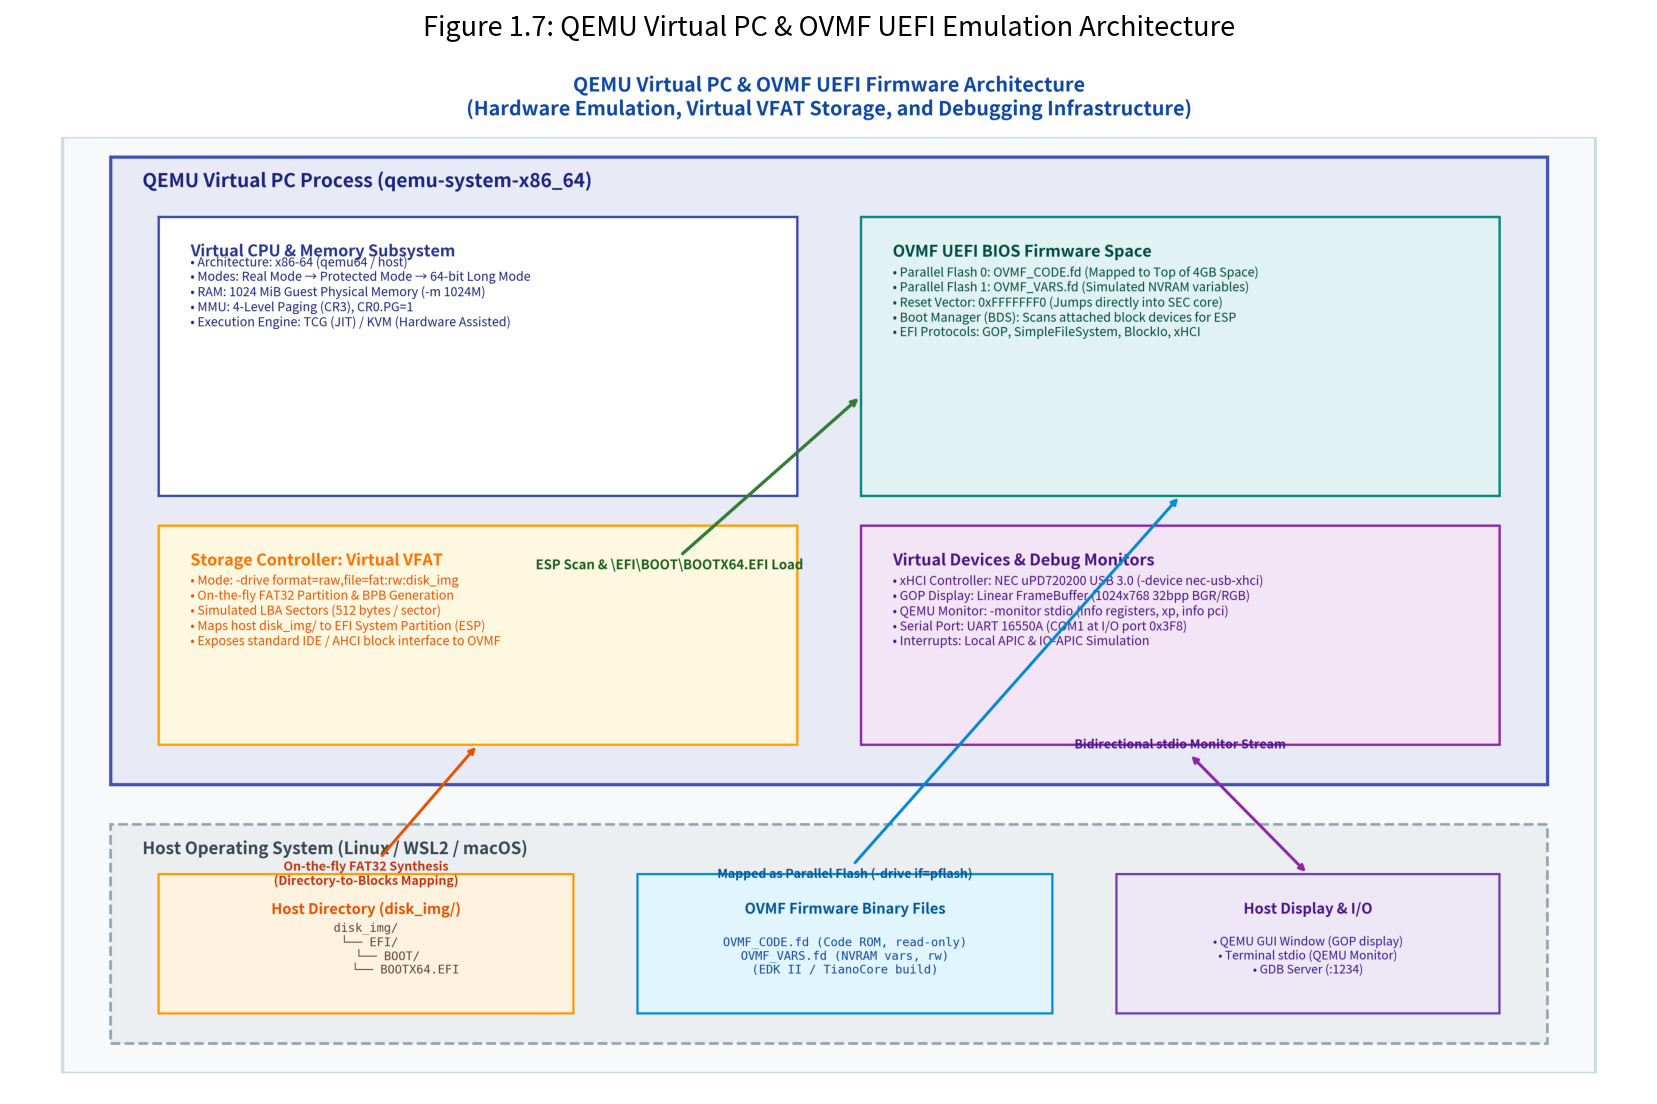

✅ 高解像度アーキテクチャ図版を保存・表示しました: result/fig1_7_qemu_ovmf_boot_architecture.png (860,464 bytes)


In [2]:
# === QEMU + OVMF 仮想PCアーキテクチャ図の生成と表示 ===
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_qemu_ovmf_boot_architecture

fig_path = Path("result/fig1_7_qemu_ovmf_boot_architecture.png")
plot_qemu_ovmf_boot_architecture(str(fig_path))

img = Image.open(fig_path)
plt.figure(figsize=(14, 9), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 1.7: QEMU Virtual PC & OVMF UEFI Emulation Architecture", fontsize=13, pad=12)
plt.show()
print(f"✅ 高解像度アーキテクチャ図版を保存・表示しました: {fig_path} ({fig_path.stat().st_size:,} bytes)")


## 2. OVMF UEFI BIOS ファームウェアとフラッシュメモリ分離構造

### OVMF (*Open Virtual Machine Firmware*) とは？
PC の電源を入れた瞬間、CPU の物理メモリ上にはまだ OS カーネルは存在しません。最初に実行されるのはマザーボード上の ROM（不揮発性メモリ）に焼き付けられたファームウェアです。レガシー PC では BIOS (*Basic Input/Output System*) でしたが、現代の PC では **UEFI** (*Unified Extensible Firmware Interface*) がその役割を担っています。

QEMU 単体はハードウェア（CPU やチップセット）の器を提供するだけであり、標準ではレガシー BIOS（SeaBIOS）をロードします。そこで、QEMU 上で UEFI 規格に準拠した 64ビット OS を起動するために、Intel やオープンソースコミュニティが策定する公式リファレンス実装 **EDK II** (*EFI Development Kit II*) からビルドされた仮想マシン用 UEFI ファームウェアが **OVMF** (*Open Virtual Machine Firmware*) です。

### なぜコードと変数を分離するのか？ (`OVMF_CODE.fd` vs `OVMF_VARS.fd`)
みかん本や本リポジトリの起動スクリプトでは、OVMF を以下の 2 つのフラッシュドライブとして指定します：

```bash
-drive if=pflash,format=raw,readonly=on,file=/usr/share/OVMF/OVMF_CODE.fd \
-drive if=pflash,format=raw,file=/usr/share/OVMF/OVMF_VARS.fd
```

| ファイル | 役割 | パーミッション | 実機ハードウェアにおける対応 |
|---|---|:---:|---|
| **`OVMF_CODE.fd`** | UEFI コアコード（SEC, PEI, DXE, BDS モジュール群、GOP・FAT ドライバ等） | 読み取り専用 (`readonly=on`) | マザーボード上の SPI NOR Flash ROM（改ざん防止・ライトプロテクト領域） |
| **`OVMF_VARS.fd`** | UEFI NVRAM 不揮発性変数領域（ブート順序 `BootOrder`、セキュアブート鍵、環境設定） | 読み書き可能 (`rw`) | バッテリバックアップ SRAM または Flash ROM 内の NVRAM エミュレーション領域 |

> [!NOTE]
> **`-bios` と `-drive if=pflash` の違い**:
> 簡易的な起動では `-bios OVMF.fd` と指定することも可能です。しかし、この方法ではファームウェア全体が単一の読み取り専用領域として扱われるため、ゲスト OS や UEFI アプリが不揮発性変数を保存（`SetVariable()` API）しようとすると失敗します。`if=pflash`（パラレルフラッシュ）を使用することで、実機と完全に同一の SPI Flash メモリマップを再現できます。


In [3]:
# === Python による QEMU 起動設定生成とパラメータの技術的解説 ===
from common import (
    QemuEmulatorConfig,
    QemuFirmwareMode,
    QemuDriveFormat,
    QemuVirtualHardwareConfig,
)

# 1. MikanOS 標準の起動構成
config_standard = QemuEmulatorConfig(
    ovmf_code_path="/usr/share/OVMF/OVMF_CODE.fd",
    ovmf_vars_path="/usr/share/OVMF/OVMF_VARS.fd",
    disk_target="disk_img",
    drive_format=QemuDriveFormat.VFAT_DIR,
    firmware_mode=QemuFirmwareMode.PFLASH_SPLIT,
    hardware=QemuVirtualHardwareConfig(
        memory_mb=1024,
        cpu_model="qemu64",
        enable_xhci=True,
        monitor_mode="stdio",
        net_mode="none",
    ),
)

print("■ 生成された QEMU 起動コマンド:")
print(f"  $ {config_standard.build_command_str()}\n")

print("■ 各起動オプションの技術的役割一覧:")
for row in config_standard.explain_parameters():
    print(f"  [{row['category']:<10}] {row['flag']:<42} : {row['explanation']}")

# バリデーション実行
errors = config_standard.validate()
assert len(errors) == 0, f"Validation failed: {errors}"
print("\n✅ 設定バリデーション: エラーゼロ (設定は完全に妥当です)")


■ 生成された QEMU 起動コマンド:
  $ qemu-system-x86_64 -m 1024M -cpu qemu64 -drive if=pflash,format=raw,readonly=on,file=/usr/share/OVMF/OVMF_CODE.fd -drive if=pflash,format=raw,file=/usr/share/OVMF/OVMF_VARS.fd -drive format=raw,file=fat:rw:disk_img -device nec-usb-xhci,id=xhci -monitor stdio -net none

■ 各起動オプションの技術的役割一覧:
  [Memory    ] -m 1024M                                   : 仮想ゲストRAMの容量。UEFIファームウェアおよびOSカーネル実行空間を確保
  [CPU       ] -cpu qemu64                                : エミュレートするCPUモデル（64ビットLong Modeサポート必須）
  [Firmware  ] -drive if=pflash,...,file=/usr/share/OVMF/OVMF_CODE.fd : OVMF UEFIコードROMを読み取り専用パラレルフラッシュメモリとしてマッピング
  [Firmware  ] -drive if=pflash,...,file=/usr/share/OVMF/OVMF_VARS.fd : UEFI NVRAM不揮発性変数領域（ブート順序や環境設定）を書き換え可能フラッシュとしてマッピング
  [Storage   ] -drive format=raw,file=fat:rw:disk_img     : ホスト上のディレクトリ 'disk_img' をQEMUがオンザフライでFAT32仮想ブロックデバイスとしてマウント
  [I/O Device] -device nec-usb-xhci,id=xhci               : USB 3.0 ホストコントローラ (xHCI) をPCIバス上に増設（MikanOS 第6章以降でマウス・キーボードを制御）
  [Debu

## 3. QEMU 仮想 FAT (`fat:rw:...`) の仕組みとオンザフライ FAT32 合成

### なぜディスクイメージファイル (`.img`) の作成が不要なのか？
一般的なエミュレータでは、OS を起動するために以下のような煩雑な前準備が必要でした：
1. `dd` や `qemu-img` で数十 MB の空ファイルを作成する。
2. `parted` や `fdisk` で MBR / GPT パーティションテーブルを書き込む。
3. `mkfs.vfat -F 32` で FAT32 ファイルシステムとしてフォーマットする。
4. `mount -o loop` でループバックマウントし、`EFI/BOOT/BOOTX64.EFI` をコピーする。
5. アンマウントして QEMU に渡す。

しかし、QEMU には **Virtual VFAT**（`fat:rw:<ディレクトリパス>`）という画期的なオンザフライ合成ストレージ機能が内蔵されています。

### QEMU 内部ドライバ (`block/vvfat.c`) の動作原理
ホスト上で `disk_img/` ディレクトリを作成し、その中に `EFI/BOOT/BOOTX64.EFI` を配置して `-drive format=raw,file=fat:rw:disk_img` と指定すると、QEMU プロセス内部のストレージレイヤが以下を自動実行します：

1. **仮想セクタの動的構築**: ホストのファイルシステムをスキャンし、メモリ上に FAT32 の規格に従った **BPB** (*BIOS Parameter Block*)、**FAT テーブル**（クラスタチェーントラッキング表）、および **ディレクトリエントリ** をリアルタイムに組み立てます。
2. **LBA セクタ要求の変換**: ゲスト OS（OVMF ファームウェア）が仮想 IDE / AHCI コントローラに対して「セクタ 32 を読み出せ」と LBA (*Logical Block Addressing*) 要求を送ると、QEMU はメモリ上の FAT テーブルを返します。「セクタ 400（ファイルの実体データ）を読み出せ」と要求されると、ホスト上の `disk_img/EFI/BOOT/BOOTX64.EFI` から該当オフセットのバイト列を直接読み出してゲストに供給します。

```text
+-----------------------------------------------------------------------------+
|               QEMU Virtual FAT32 LBA Sector Layout (512B / sector)          |
+------------+---------------+---------------+---------------+---------------+
|  Sector 0  | Sectors 1-31  | Sectors 32-N  | Sectors N-2N  | Clusters 2..M |
|    MBR     |   Reserved    |     FAT #1    |  FAT #2 (Mir) |   Data Area   |
| (ESP 0xEF) |  (BPB/FSInfo) | (Cluster Map) | (Backup Copy) | (Dirs & Files)|
+------------+---------------+---------------+---------------+---------------+
                                                                |-- Cluster 2: Root Directory ('EFI' dir entry)
                                                                |-- Cluster 3: EFI Directory ('BOOT' dir entry)
                                                                |-- Cluster 4: BOOT Directory ('BOOTX64.EFI')
                                                                `-- Clusters 5+: BOOTX64.EFI Raw Machine Code
```

> [!WARNING]
> **仮想 FAT (VFAT) の注意点と落とし穴**:
> - **書き込みデータの遅延と不整合**: ゲスト OS が仮想 FAT ドライブにファイルを書き込んだ場合、QEMU プロセス内のメモリキャッシュに一時保持され、ホストファイルへ書き戻す際にタイミングのズレが生じる場合があります。ホストとゲストから同一ファイルを同時に変更してはいけません。
> - **動的更新の反映**: QEMU が起動している最中にホスト側で新しくファイルを追加した場合、QEMU が初期起動時に構築した FAT テーブルのセクタ割り当てと矛盾が生じるため、ゲスト側の UEFI からは見えないことがあります。ファイルを入れ替えた場合は QEMU を再起動するのが鉄則です。


In [4]:
# === Python による QEMU 仮想 FAT32 パーティション・クラスタ配置シミュレーション ===
from common import VirtualFatSimulator

vfat = VirtualFatSimulator(host_dir="disk_img")

# 配置するファイル一覧とそのサイズ (バイト)
sim_files = {
    "EFI/BOOT/BOOTX64.EFI": 1488,   # 第1章最小ハローワールドバイナリ
    "mikanos.log": 512,             # 起動ログファイル
}

layout = vfat.simulate_vfat_layout(sim_files)

print("■ 仮想 FAT32 パラメータ:")
print(f"  - セクタサイズ            : {layout['sector_size']} bytes")
print(f"  - クラスタサイズ          : {layout['cluster_size_bytes']} bytes ({layout['sectors_per_cluster']} sectors/cluster)")
print(f"  - 予約セクタ数 (Reserved) : {layout['reserved_sectors']} sectors")
print(f"  - FAT テーブル数          : {layout['num_fats']} (Primary + Backup)")
print(f"  - 仮想ディスク容量        : {layout['total_capacity_mb']} MB ({layout['total_sectors']:,} sectors)\n")

print("■ クラスタ割り当てマップ (Cluster Allocation Table):")
for path, alloc in layout["cluster_allocations"].items():
    clusters_str = ", ".join(f"#{c}" for c in alloc["clusters"])
    print(f"  {path:<24} -> 開始クラスタ: #{alloc['start_cluster']}, クラスタ列: [{clusters_str}] ({alloc['size_bytes']:,} bytes)")

print("\n■ QEMU VFAT 特有の制限事項:")
for i, lim in enumerate(layout["vfat_limitations"], 1):
    print(f"  {i}. {lim}")


■ 仮想 FAT32 パラメータ:
  - セクタサイズ            : 512 bytes
  - クラスタサイズ          : 4096 bytes (8 sectors/cluster)
  - 予約セクタ数 (Reserved) : 32 sectors
  - FAT テーブル数          : 2 (Primary + Backup)
  - 仮想ディスク容量        : 0.57 MB (1,160 sectors)

■ クラスタ割り当てマップ (Cluster Allocation Table):
  /                        -> 開始クラスタ: #2, クラスタ列: [#2] (4,096 bytes)
  EFI/BOOT/BOOTX64.EFI     -> 開始クラスタ: #3, クラスタ列: [#3] (1,488 bytes)
  mikanos.log              -> 開始クラスタ: #4, クラスタ列: [#4] (512 bytes)

■ QEMU VFAT 特有の制限事項:
  1. 書き込み遅延: QEMUプロセスのメモリ上にキャッシュされるため、ホストとゲストで同時編集するとデータ不整合が発生する
  2. 動的反映の制限: QEMU起動後にホスト側で追加した新規ファイルは再起動するまでゲストUEFIから見えない場合がある
  3. ファイル名の大文字小文字: FAT32 Short Name (8.3形式) と Long File Name (LFN) の変換が発生する


## 4. 電源投入から MikanOS 実行までの完全ブートシーケンス

仮想マシンを起動してから、画面に `Hello, world!` が表示されるまでには、UEFI プラットフォーム標準仕様に基づく厳格な **6大フェーズ** が実行されます。

```mermaid
sequenceDiagram
    autonumber
    participant CPU as 仮想 x86-64 CPU
    participant SEC as 1. SEC Phase (Security)
    participant PEI as 2. PEI Phase (Pre-EFI Init)
    participant DXE as 3. DXE Phase (Driver Exec)
    participant BDS as 4. BDS Phase (Boot Selection)
    participant VFAT as QEMU Virtual FAT
    participant APP as MikanOS (BOOTX64.EFI)

    CPU->>SEC: Reset Vector (0xFFFFFFF0) から実行開始
    Note over SEC: リアルモード, Cache-As-RAM 設定
    SEC->>PEI: メインメモリ検出とチップセット初期化要求
    Note over PEI: 1024MB RAM初期化, プロテクトモード移行
    PEI->>DXE: 64-bit Long Mode ページング確立
    Note over DXE: GOP / PCI / xHCI / FAT ドライバロード
    DXE->>BDS: プラットフォームブートマネージャ起動
    BDS->>VFAT: 接続デバイスから ESP (EFI System Partition) 探索
    VFAT-->>BDS: \EFI\BOOT\BOOTX64.EFI ファイルを返却
    BDS->>APP: PE32+ ヘッダを解析しメモリ展開、EfiMain へジャンプ！
    APP-->>CPU: ConOut->OutputString(SystemTable, L"Hello, world!\n")
```

### 各フェーズにおけるハードウェア・レジスタ状態の遷移
1. **SEC (*Security*) フェーズ**: 電源投入またはリセット信号により、x86-64 CPU は 16ビットリアルモード互換状態でアドレス `0x00000000FFFFFFF0`（リセットベクタ）の命令を実行します。この番地には QEMU のパラレルフラッシュによって `OVMF_CODE.fd` のエントリポイントがマッピングされており、CPU キャッシュを一時スタックとして利用する CAR (*Cache-As-RAM*) が構成されます。
2. **PEI (*Pre-EFI Initialization*) フェーズ**: 最小限のハードウェア（Q35/i440FX チップセットとメモリコントローラ）を初期化し、QEMU に割り当てた 1024 MiB の仮想 RAM を使用可能にします。CPU は 32ビットプロテクトモードへ遷移します。
3. **DXE (*Driver Execution Environment*) フェーズ**: 4階層ページテーブル（CR3 レジスタ）を設定して 64ビット **Long Mode** へ切り替えます。GOP（画面描画）、PCI バス走査、xHCI（USB 3.0）、および FAT ファイルシステムドライバが次々と実行環境にディスパッチされます。
4. **BDS (*Boot Device Selection*) フェーズ**: ブートマネージャが接続されたストレージを順に走査し、FAT32 フォーマットされた EFI システムパーティション（ESP）をマウントします。
5. **TSL (*Transient System Load*) フェーズ**: UEFI 仕様で定められたデフォルトパス `\EFI\BOOT\BOOTX64.EFI` をオープンし、PE32+ 形式のバイナリヘッダを読み込みます。メモリの空きページを確保し、コードセグメント（`.text`）およびデータセグメント（`.data`）を再配置（Relocation）します。
6. **RT (*Runtime*) フェーズ**: UEFI は `BOOTX64.EFI` のエントリポイント（`EfiMain`）へ関数呼び出し（`CALL` 命令）を行い、OS アプリケーションの実行が開始されます！


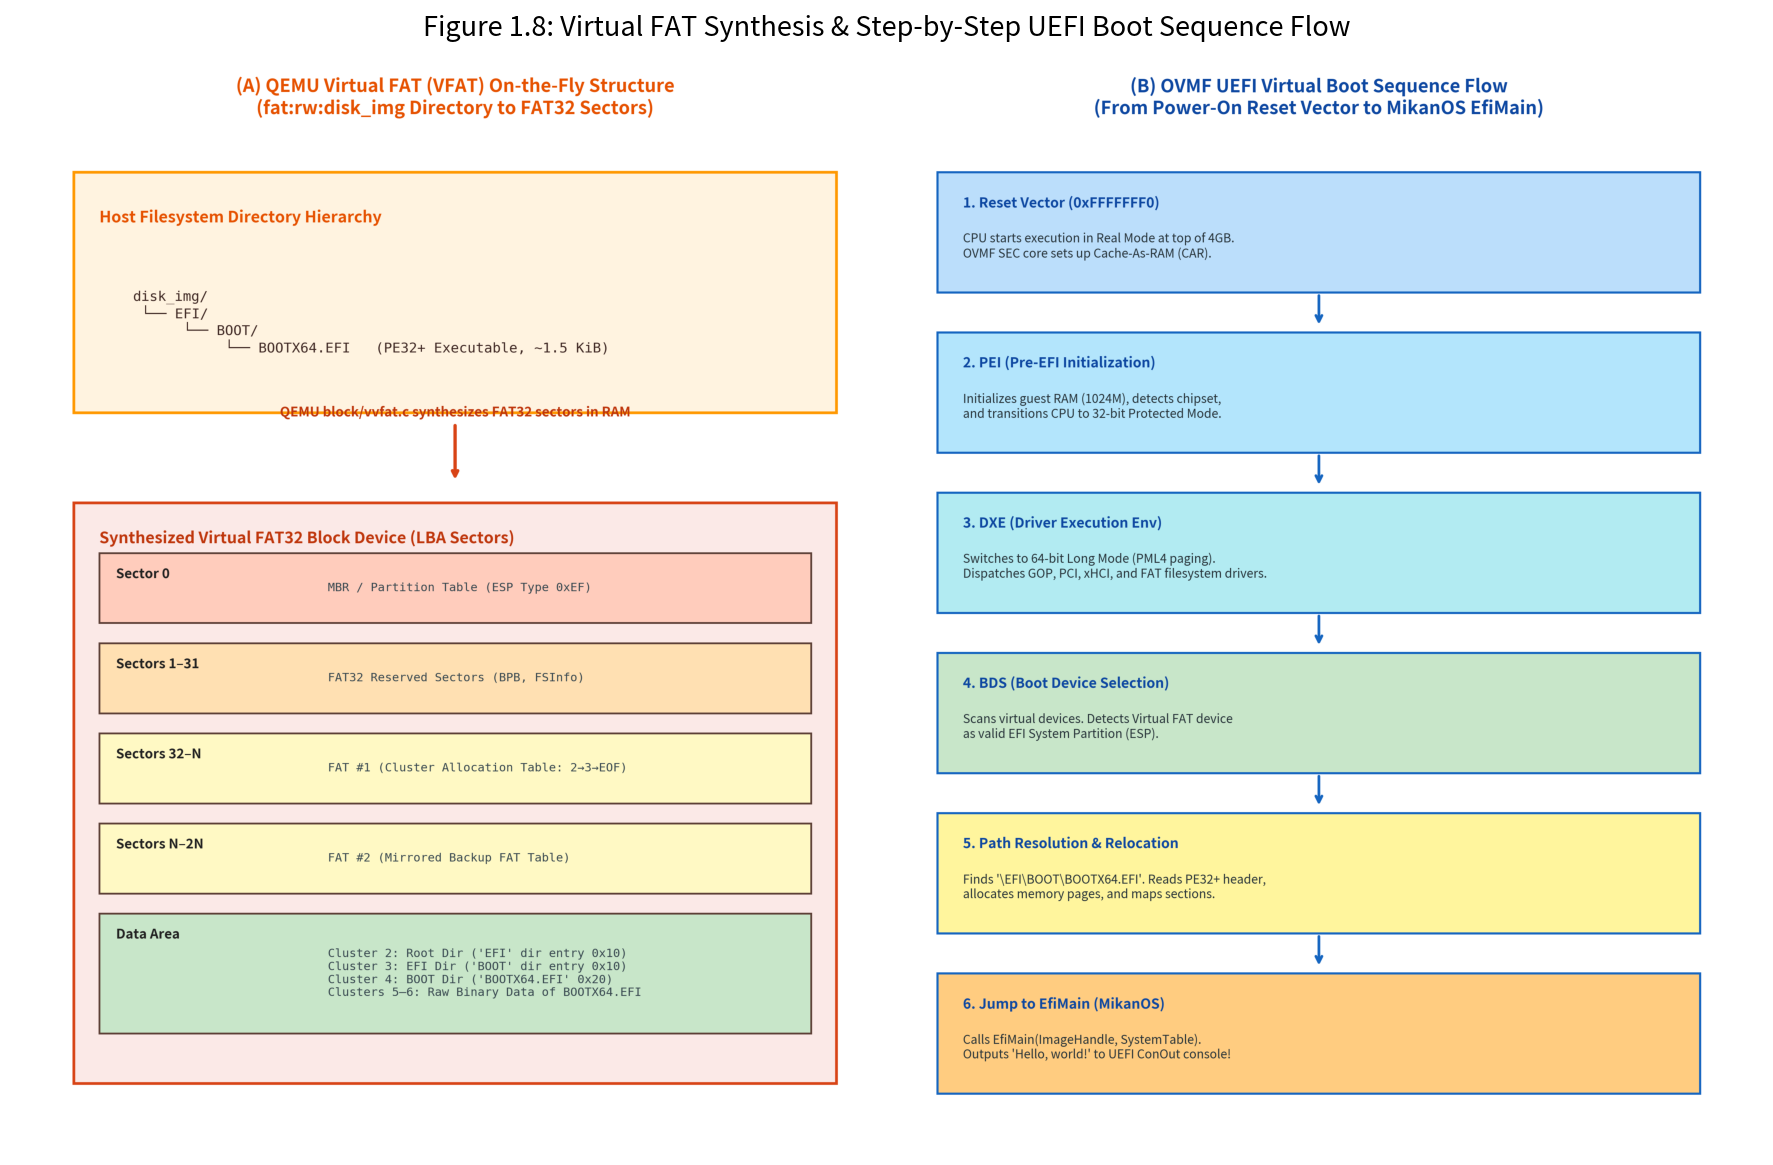

■ UEFI プラットフォームブートシーケンス詳細ステップ:
Step 1: [Security (SEC)] CPU Reset Vector Execution 
  概要: QEMU仮想CPUにリセット信号が投入され、x86-64プロセッサは0xFFFFFFF0番地（Reset Vector）からOVMF SECコードを実行開始。CAR（Cache-As-RAM）を設定。
  ハードウェア状態: RIP=0x00000000FFFFFFF0, CR0=0x00000010 (Real Mode / No Paging), RAM=未初期化, Firmware=OVMF_CODE.fd

Step 2: [Pre-EFI Initialization (PEI)] Pre-EFI Initialization & Memory Discovery 
  概要: OVMF PEIモジュールがQEMU仮想マザーボードのQ35/i440FXチップセットおよび仮想RAM（-m 1024M）を検出し、4GiB空間の物理メモリ初期化とページングを有効化。
  ハードウェア状態: RIP=0x00000000008xxxxx, CR0=0x8001003B (Protected Mode / Paging), RAM=1024 MiB 有効化, Firmware=OVMF PEI

Step 3: [Driver Execution Environment (DXE)] Driver Execution Environment & Protocol Dispatch 
  概要: OVMF DXEコアが起動。64ビットLong Modeへ移行し、GOP（Graphics Output Protocol）、PCIドライバ、xHCIドライバ、FATファイルシステムドライバをメモリ上に順次ロード。
  ハードウェア状態: RIP=0x0000000007xxxxxx, CR0=0x80010033 (64-bit Long Mode), CR3=PML4 Page Table, Firmware=OVMF DXE Protocols

Step 4: [Boot Device Selection (BDS)] Boot Device Selection & ESP Partitio

In [5]:
# === 仮想 FAT 合成と UEFI ブートシーケンス図の表示 & ステップ検証 ===
from PIL import Image
import matplotlib.pyplot as plt
from common import (
    plot_virtual_fat_and_boot_flow,
    QemuUefiBootSequenceSimulator,
)

fig_path = Path("result/fig1_8_virtual_fat_and_boot_flow.png")
plot_virtual_fat_and_boot_flow(str(fig_path))

img = Image.open(fig_path)
plt.figure(figsize=(15, 9.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 1.8: Virtual FAT Synthesis & Step-by-Step UEFI Boot Sequence Flow", fontsize=13, pad=12)
plt.show()

print("■ UEFI プラットフォームブートシーケンス詳細ステップ:")
steps = QemuUefiBootSequenceSimulator.get_boot_sequence()
for s in steps:
    target_mark = "🌟 [MikanOS Target]" if s.is_mikanos_target else ""
    print(f"Step {s.step_number}: [{s.phase.value}] {s.title} {target_mark}")
    print(f"  概要: {s.description}")
    state_str = ", ".join(f"{k}={v}" for k, v in s.hardware_state.items())
    print(f"  ハードウェア状態: {state_str}\n")


## 5. QEMU モニタ — OS 自作における最強のデバッグ武器

### なぜ QEMU モニタが必須なのか？
画面描画や文字出力ドライバ（第5章の `printk`）が完成する前の OS 自作初期段階では、カーネルがどこまで動いてどこで停止したかを調べる手段がありません。
起動パラメータに `-monitor stdio` を指定すると、QEMU を起動したターミナルが **対話型デバッグコンソール（QEMU モニタ）** に切り替わり、仮想マシンの実行を止めることなく CPU レジスタ、物理メモリ、PCI デバイスの状態を直接覗き見ることができます。

### 必須デバッグコマンド一覧

| コマンド | 書式例 | 動作とデバッグ時の活用法 |
|---|---|---|
| `info registers` | `(qemu) info registers` | 全 CPU 汎用レジスタ（`RAX`〜`R15`）、命令ポインタ（`RIP`）、スタックポインタ（`RSP`）、および制御レジスタ（`CR0`, `CR3`, `CR4`）を一括ダンプする。クラッシュ時にどの命令アドレスで停止したかを特定する基本コマンド。 |
| `xp` (*eXamine Physical*) | `(qemu) xp /16xb 0x067e4000` | 指定したゲスト**物理アドレス**から生バイト列をダンプする。`0x5A4D`（PE32+ MZ ヘッダ）やフレームバッファのピクセルデータが正しくメモリ配置されているかを確認する。 |
| `info pci` | `(qemu) info pci` | 仮想マザーボードに接続されている全 PCI デバイスの Bus / Device / Function 番号とベンダーID・デバイスIDを表示する。第6章の xHCI コントローラ探索で威力を発揮する。 |
| `info block` | `(qemu) info block` | QEMU にマウントされているブロックストレージ（仮想 FAT ドライブ等）の認識状態を表示する。 |
| `system_reset` | `(qemu) system_reset` | 仮想マザーボードのハードウェアリセットをトリガーし、QEMU プロセスを終了させずに Reset Vector から再ブートする。 |
| `quit` (または `q`) | `(qemu) q` | 仮想マシンを即座に終了し、ホストシェルに復帰する。 |


In [6]:
# === Python による QEMU モニタコマンドの対話的検査シミュレーション ===
from common import QemuMonitorSimulator

commands_to_test = [
    "info registers",
    "xp /16xb 0x067e4000",
    "info pci",
    "info block",
]

for cmd in commands_to_test:
    result = QemuMonitorSimulator.execute_command(cmd)
    print(f"(qemu) {result['command']}")
    print(f"[解説: {result['explanation']}]")
    print(result['output'])
    print("-" * 70)


(qemu) info registers
[解説: 64ビット汎用レジスタ、命令ポインタ(RIP)、およびページング制御レジスタ(CR0/CR3/CR4)の状態を表示]
RAX=0000000000000000 RBX=00000000067ea018 RCX=00000000067ea018 RDX=00000000067ed018
RSI=0000000000000000 RDI=0000000000000000 RBP=0000000007fa7f50 RSP=0000000007fa7f10
R8 =0000000000000000 R9 =0000000000000000 R10=0000000000000000 R11=0000000000000000
R12=0000000000000000 R13=0000000000000000 R14=0000000000000000 R15=0000000000000000
RIP=00000000067e4010 RFL=00000202 [-------] CPL=0 II=0 A20=1 SMM=0 HLT=0
CR0=80010033 CR2=0000000000000000 CR3=0000000007e01000 CR4=00000668
----------------------------------------------------------------------
(qemu) xp /16xb 0x067e4000
[解説: 物理メモリ番地（Physical Memory）の生バイト列を直接ダンプ（PE32+ MZマジックナンバー 0x5A4D の確認）]
00000000067e4000: 0x4d 0x5a 0x90 0x00 0x03 0x00 0x00 0x00  MZ......
00000000067e4008: 0x04 0x00 0x00 0x00 0xff 0xff 0x00 0x00  ........
----------------------------------------------------------------------
(qemu) info pci
[解説: QEMU仮想マザーボード上のPCIデバイス一覧を表示（xHCIコントローラのB

## 6. C++20 による QEMU 起動設定ビルダー & FAT32 構造体の検証

OS のコアロジックやファイルシステムドライバ（第17章）を実装する際、ハードウェア仕様書や規格書に定義されたビットフィールドを 1 バイトのズレもなく C++ 構造体として定義する必要があります。

ホスト側検証コード `src/ch01/qemu_launch_builder.cpp` では、以下を C++20 で実装・検証しています：
1. `#pragma pack(push, 1)` によるコンパイラパディングの無効化と、FAT32 BPB（90バイト）およびディレクトリエントリ（32バイト）のメモリ整合性検証（`static_assert`）。
2. QEMU 起動引数のビルダーパターン実装と、不正なパラメータ（メモリ不足、パス未設定など）の厳格なバリデーション。

以下のセルを実行して、C++20 コードのコンパイルと単体テストを実行します。


In [7]:
# === C++20 QEMU Launch Builder & FAT32 構造体のコンパイルと実行 ===
import subprocess
from pathlib import Path

cpp_source = Path("../src/ch01/qemu_launch_builder.cpp")
bin_target = Path("../build/bin/ch01_qemu_launch_builder")

if not bin_target.exists():
    print("CMake ターゲットをビルド中...")
    subprocess.run(["cmake", "--build", "../build", "--target", "ch01_qemu_launch_builder"], check=True)

print(f"バイナリを実行中: {bin_target} ...\n")
res = subprocess.run([str(bin_target)], capture_output=True, text=True, check=True)
print(res.stdout)


バイナリを実行中: ../build/bin/ch01_qemu_launch_builder ...

  MikanOS C++20 QEMU Launch Builder & FAT32 Inspector   

[Step 1] Validating FAT32 BPB & Directory Entry Structures...
  - Fat32Bpb size: 90 bytes (OK)
  - Cluster size : 4096 bytes (OK)
  - FatDirectoryEntry size: 32 bytes (OK)
  - Entry name   : BOOTX64 EFI
  - Start cluster: 4 (OK)

[Step 2] Testing QEMU Command Construction (MikanOS Standard)...
  - Total arguments: 17
  - Command line:
    qemu-system-x86_64 -m 1024M -cpu qemu64 -drive if=pflash,format=raw,readonly=on,file=/usr/share/OVMF/OVMF_CODE.fd -drive if=pflash,format=raw,file=/usr/share/OVMF/OVMF_VARS.fd -drive format=raw,file=fat:rw:disk_img -device nec-usb-xhci,id=xhci -monitor stdio -net none

[Step 3] Testing -bios direct loading mode...
  - Command line:
    qemu-system-x86_64 -m 1024M -cpu qemu64 -bios /path/to/OVMF.fd -drive format=raw,file=fat:rw:disk_img -device nec-usb-xhci,id=xhci -monitor stdio -net none

[Step 4] Testing GDB remote debugging mode (-gdb tcp:

## 7. 理解度セルフチェック演習（即時自己採点）

本節で学んだ QEMU 仮想マシンの仕組み、OVMF の Flash 分離、仮想 FAT の動作、およびブートシーケンスについて、以下の設問に解答してください。

### 設問一覧
1. **Q1**: QEMU で OVMF ファームウェアをロードする際、`-bios OVMF.fd` 単一指定に比べて `-drive if=pflash,...` で `OVMF_CODE.fd` と `OVMF_VARS.fd` を分離指定する決定的な技術的メリットは何ですか？
2. **Q2**: QEMU の仮想 FAT 機能（`-drive format=raw,file=fat:rw:disk_img`）において、ホストディレクトリからオンザフライで生成されるファイルシステムの種別は何ですか？
3. **Q3**: x86-64 CPU に電源が投入された直後、プロセッサがリアルモード互換で最初にフェッチする命令のアドレス（Reset Vector）はどこですか？
4. **Q4**: QEMU 実行中にターミナル（stdio モニタ）から CPU レジスタ群（RAX, RIP, CR0, CR3 等）をダンプするためのコマンドは何ですか？


In [8]:
# === 理解度クイズの解答入力と自己採点 ===

# 以下の変数に適切な選択肢のアルファベット ('A', 'B', 'C', 'D') を設定してください
ans_q1 = "B"  # A: 高速起動できる, B: NVRAM変数の書き込み永続化が可能になる, C: 32bit専用になる, D: GUIが不要になる
ans_q2 = "C"  # A: ext4, B: NTFS, C: FAT32 (またはFAT16), D: ISO9660
ans_q3 = "A"  # A: 0xFFFFFFF0, B: 0x00000000, C: 0x00007C00, D: 0x00100000
ans_q4 = "D"  # A: dump cpu, B: show registers, C: reg dump, D: info registers

# 自動採点ロジック
score = 0
assert ans_q1 == "B", "Q1 不正解: pflash 分離により NVRAM 不揮発性変数領域を rw で永続化できます"
score += 25

assert ans_q2 == "C", "Q2 不正解: QEMU VFAT は EFI System Partition 互換の FAT32/FAT16 をオンザフライ合成します"
score += 25

assert ans_q3 == "A", "Q3 不正解: x86-64 CPU のリセットベクタは 4GB 空間の最上位付近 0xFFFFFFF0 番地です"
score += 25

assert ans_q4 == "D", "Q4 不正解: QEMU モニタでレジスタをダンプするコマンドは 'info registers' です"
score += 25

print(f"🎉 おめでとうございます！全問正解です！ 獲得スコア: {score} / 100 点")


🎉 おめでとうございます！全問正解です！ 獲得スコア: 100 / 100 点


## 8. 本節のまとめと次節（1.5 節）への展望

### 本節で学んだ重要概念 (Key Takeaways)
1. **エミュレータによる超高速開発サイクル**: 実機の再起動・ブートメニュー選択・物理メディア抜き差しを排除し、コマンド 1 つで数十ミリ秒でテスト可能な環境を構築しました。
2. **OVMF のコードと変数の分離**: 実機のマザーボード SPI Flash と同様に、`OVMF_CODE.fd`（読み取り専用コード ROM）と `OVMF_VARS.fd`（書き換え可能 NVRAM 変数領域）をパラレルフラッシュ（`if=pflash`）としてマッピングする重要性を学びました。
3. **QEMU 仮想 FAT の強力さ**: ディスクイメージ作成やループバックマウントを行わずとも、ホスト上の `disk_img/EFI/BOOT/BOOTX64.EFI` がオンザフライで FAT32 ボリュームとしてゲストに提供される仕組みを解き明かしました。
4. **UEFI ライフサイクルの全体像**: CPU リセットベクタ `0xFFFFFFF0` から、SEC → PEI → DXE → BDS を経て、ESP 内の `BOOTX64.EFI` がロードされ、`EfiMain` へジャンプするまでの流れを整理しました。
5. **QEMU モニタによる不可視の打破**: `info registers`, `xp`, `info pci` を用いて、OS 初期開発におけるデバッグ手法の基礎を確立しました。

### 次節への展望 (Next Step)
次節 **1.5 結局、何をやったのか？** では、1.1 のバイナリ作成から 1.4 の QEMU 実行までの一連のプロセスを総括し、CPU リセットからファームウェアが起動し、ファイルシステムを解釈してアプリケーションへ制御を渡す「ブートの全貌」をより巨視的な視点から体系化します！
